## Create numpy array of alzheimer patiant.

### Test yolo face detection


image 1/1 /Users/isakhamrin/Programmering/year5/project_course/Scientific-computing-project---Emotion-detection/data/test_image.png: 640x640 1 face, 63.7ms
Speed: 4.3ms preprocess, 63.7ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)


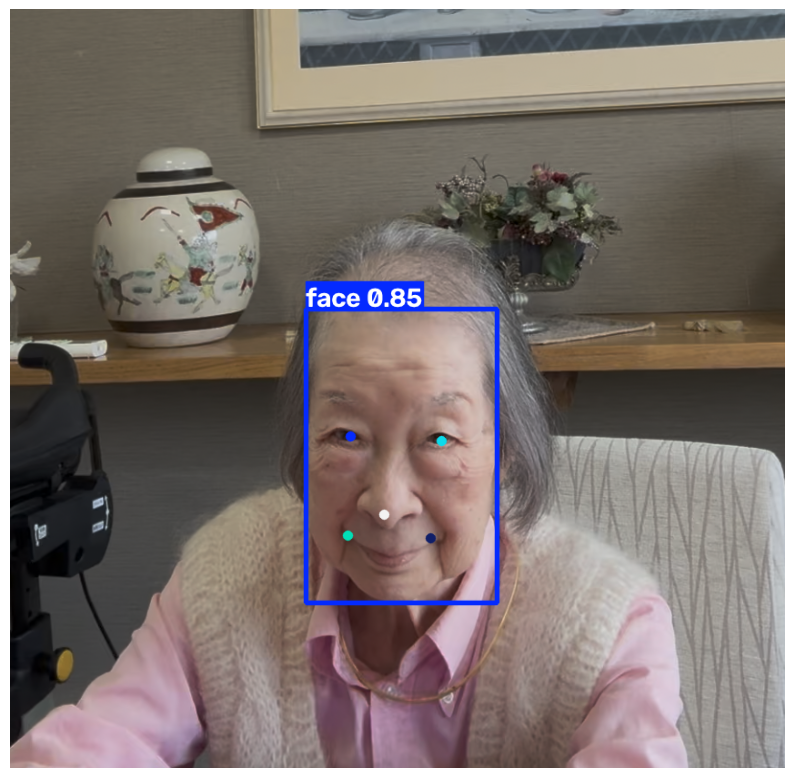

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load the YOLO model
model = YOLO("models/yolov8n-face.pt")

# Run prediction on an image
results = model.predict(source="data/test_image.png", conf=0.5)

# Get the annotated frame (returns a BGR numpy array)
annotated_frame = results[0].plot()

# Convert BGR (OpenCV format) to RGB (Matplotlib format)
annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

# Plot the image inline beneath the cell
plt.figure(figsize=(10, 10))
plt.imshow(annotated_frame_rgb)
plt.axis("off")  # Hide axis ticks
plt.show()

In [ ]:
# Cut long videos into ~4 s segments, preprocess each segment exactly like the training cache
# (32 evenly spaced frames -> one face box -> 160x160 uint8 .npy), then run the fine-tuned model on every segment.
# No decord needed: frames are read with OpenCV, one sequential pass per video, so 20-minute videos are fine.
#
# Folder layout (run from the folder that contains these):
#   data/            your videos (.mp4 .mov .avi .mkv ...)
#   models/best.pth  fine-tuned weights
#   MAE-DFER/        git clone https://github.com/sunlicai/MAE-DFER.git   (only modeling_finetune.py is needed)
#
# Setup:  pip install torch torchvision timm==0.4.12 einops opencv-python-headless numpy matplotlib
# Run:    python infer_long_videos.py
#
# Output: cache/<video>/<video>_<start>s.npy   (32,160,160,3) uint8 per segment + index.csv
#         results/<video>_predictions.csv      probabilities per segment (+ start/end time)
#         results/<video>_timeline.png         probability-over-time plot

import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # unsupported MPS ops fall back to CPU instead of crashing

import sys, glob, csv, time
import numpy as np
import cv2
import torch

cv2.ocl.setUseOpenCL(False)
cv2.setNumThreads(0)

# ============================ CONFIG ============================
REPO_DIR   = 'MAE-DFER'
CKPT       = 'models/MAE_DFER-ElderReact.pth'
DATA_DIR   = 'data'
CACHE_DIR  = 'cache'
OUT_DIR    = 'results'

SEGMENT_SEC = 4.0        # length of one "item"
STRIDE_SEC  = 4.0        # = SEGMENT_SEC: no overlap. Smaller (e.g. 2.0) = overlapping windows, more segments
USE_FACE_CROP = True
SKIP_NO_FACE  = False    # True: drop segments where no face was found (instead of using the whole frame)

RUN_INFERENCE = True     # False = only build the .npy cache
BATCH_SIZE    = 8
THR, MIN_K, MAX_K = 0.5, 0, 0     # decision rule for the "predicted" column (MAX_K=0 -> no limit)
MAKE_PLOTS    = True
DEVICE = 'auto'          # 'auto' = Apple GPU (mps) if available, else cpu; or force 'cpu' / 'mps'
# =================================================================

# ---- must match training ----
MODEL_NAME = 'vit_base_dim512_no_depth_patch16_160'
DEPTH, ATTN_TYPE, LG_REGION_SIZE, LG_CLASSIFY_TOKEN_TYPE = 16, 'local_global', [2, 5, 10], 'region'
EMOTIONS = ['anger', 'disgust', 'fear', 'happiness', 'sadness', 'surprise']
NUM_FRAMES, TUBELET, SIZE, N_CACHE_FRAMES = 16, 2, 160, 32
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
VIDEO_EXTS = ('.mp4', '.mov', '.avi', '.mkv', '.webm', '.m4v')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


# _face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
from ultralytics import YOLO

YOLO_FACE_MODEL = 'models/yolov8n-face.pt'
_face_detector = YOLO(YOLO_FACE_MODEL)

def extract_features(model, batch):
    features = []

    def hook(module, inputs):
        features.append(inputs[0].detach())

    handle = model.head.register_forward_pre_hook(hook)

    with torch.no_grad():
        logits = model(batch)

    handle.remove()

    # Expected: (batch_size, 512)
    features = features[0]

    return features.cpu().numpy(), torch.sigmoid(logits).cpu().numpy()

# ------------------------- preprocessing -------------------------
# def face_box(frame, margin=0.3):
#     gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
#     try:
#         faces = _face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
#     except cv2.error:
#         return None
#     if len(faces) == 0:
#         return None
#     x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
#     H, W = frame.shape[:2]
#     s = int(max(w, h) * (1 + margin)); cx, cy = x + w // 2, y + h // 2
#     x0, y0 = max(0, cx - s // 2), max(0, cy - s // 2)
#     return x0, y0, min(W, x0 + s), min(H, y0 + s)

def face_box(frame, margin=0.3):
    """
    Detect the largest face using YOLO.
    Input: RGB image.
    Output: x0, y0, x1, y1.
    """

    H, W = frame.shape[:2]

    # Ultralytics expects an OpenCV-style BGR image
    bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

    results = _face_detector.predict(
        source=bgr,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes is None or len(boxes) == 0:
        return None

    # Select largest detected face
    xyxy = boxes.xyxy.cpu().numpy()

    x1, y1, x2, y2 = max(
        xyxy,
        key=lambda b: (b[2] - b[0]) * (b[3] - b[1])
    )

    # Add margin around face
    w = x2 - x1
    h = y2 - y1

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    size = max(w, h) * (1 + margin)

    x0 = max(0, int(cx - size / 2))
    y0 = max(0, int(cy - size / 2))
    x1 = min(W, int(cx + size / 2))
    y1 = min(H, int(cy + size / 2))

    return x0, y0, x1, y1


def save_segment(frames, start_s, end_s, out_dir, stem):
    """frames: list of N_CACHE_FRAMES RGB uint8 frames. Same steps as the training cache."""
    box = None
    if USE_FACE_CROP:
        for j in (len(frames) // 2, len(frames) // 4, 3 * len(frames) // 4):   # try a few frames
            box = face_box(frames[j])
            if box:
                break
        if box is None and SKIP_NO_FACE:
            return None
    if box:
        x0, y0, x1, y1 = box
        frames = [f[y0:y1, x0:x1] for f in frames]
    arr = np.stack([cv2.resize(f, (SIZE, SIZE)) for f in frames]).astype(np.uint8)   # 32,160,160,3
    fname = f'{stem}_{start_s:09.2f}s.npy'
    np.save(os.path.join(out_dir, fname), arr)
    return dict(file=fname, start_s=round(start_s, 2), end_s=round(end_s, 2), face_found=int(box is not None))


def preprocess_video(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    out_dir = os.path.join(CACHE_DIR, stem)
    index_path = os.path.join(out_dir, 'index.csv')
    if os.path.isfile(index_path):
        print(f'[{stem}] cache already built ({index_path}) - skipping preprocessing')
        return out_dir
    os.makedirs(out_dir, exist_ok=True)

    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise RuntimeError(f'OpenCV cannot open {path} (unsupported codec? try re-encoding with ffmpeg to h264 mp4)')
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if n_frames <= 0:
        raise RuntimeError(f'could not read the frame count of {path}')
    seg_len = max(N_CACHE_FRAMES, int(round(SEGMENT_SEC * fps)))
    stride = max(1, int(round(STRIDE_SEC * fps)))
    starts = list(range(0, n_frames - seg_len + 1, stride))
    print(f'[{stem}] {n_frames} frames, {fps:.1f} fps, {n_frames / fps / 60:.1f} min -> {len(starts)} segments of {seg_len / fps:.1f}s')
    if not starts:
        raise RuntimeError('video is shorter than one segment')

    # which frame numbers are needed, and by which segment/position
    needed = {}
    for si, s0 in enumerate(starts):
        idx = s0 + ((np.arange(N_CACHE_FRAMES) + 0.5) / N_CACHE_FRAMES * seg_len).astype(int)
        for pos, fi in enumerate(idx):
            needed.setdefault(int(fi), []).append((si, pos))
    last_needed = max(needed)

    buffers, filled, rows = {}, {}, []
    t0 = time.time()
    fi = 0
    while fi <= last_needed:
        if fi in needed:
            ok, bgr = cap.read()
            if not ok:
                break
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            for si, pos in needed[fi]:
                buf = buffers.setdefault(si, [None] * N_CACHE_FRAMES)
                buf[pos] = rgb
                filled[si] = filled.get(si, 0) + 1
                if filled[si] == N_CACHE_FRAMES:
                    s0 = starts[si]
                    row = save_segment(buf, s0 / fps, (s0 + seg_len) / fps, out_dir, stem)
                    if row:
                        rows.append(row)
                    del buffers[si], filled[si]
        else:
            if not cap.grab():
                break
        fi += 1
        if fi % 3000 == 0:
            print(f'   frame {fi}/{last_needed} | {len(rows)} segments saved | {time.time() - t0:.0f}s', end='\r')
    cap.release()
    print(f'\n[{stem}] saved {len(rows)} segments in {time.time() - t0:.0f}s '
          f'({sum(1 for r in rows if not r["face_found"])} without a face)'
          + (f' | {len(buffers)} incomplete segments dropped' if buffers else ''))

    rows.sort(key=lambda r: r['start_s'])
    with open(index_path, 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=['file', 'start_s', 'end_s', 'face_found'])
        w.writeheader(); w.writerows(rows)
    return out_dir


# ------------------------- model + inference -------------------------
def load_model(device):
    sys.path.append(REPO_DIR)
    import modeling_finetune  # noqa: F401
    from timm.models import create_model
    model = create_model(MODEL_NAME, pretrained=False, num_classes=len(EMOTIONS),
                         all_frames=NUM_FRAMES, tubelet_size=TUBELET, drop_path_rate=0.0,
                         depth=DEPTH, attn_type=ATTN_TYPE, lg_region_size=LG_REGION_SIZE,
                         lg_classify_token_type=LG_CLASSIFY_TOKEN_TYPE)
    ck = torch.load(CKPT, map_location='cpu', weights_only=False)
    model.load_state_dict(ck['model'], strict=True)          # any mismatch fails loudly
    print(f'loaded {CKPT} (epoch {ck.get("epoch")}, {ck.get("metric")}={ck.get("score")})')
    return model.to(device).eval()


def decide(probs, thr, min_k, max_k):
    pred = probs >= thr
    rank = np.argsort(np.argsort(-probs, axis=1), axis=1)
    if max_k:
        pred &= rank < max_k
    if min_k:
        pred |= rank < min_k
    return pred


def fmt_time(s):
    return f'{int(s // 60):02d}:{s % 60:05.2f}'

def save_gradcam(model, cache_dir, row, stem, target_class=None):
    import torch.nn.functional as F
    import matplotlib.pyplot as plt

    # Load the original cached segment (32, 160, 160, 3)
    arr = np.load(os.path.join(cache_dir, row['file']))

    # Same 16 frames used during inference
    frames = arr[::2]

    # Same normalization as inference
    x = (frames.astype(np.float32) / 255.0 - MEAN) / STD

    # (1, 3, 16, 160, 160)
    x = torch.from_numpy(
        np.ascontiguousarray(x.transpose(3, 0, 1, 2))
    ).unsqueeze(0).to(next(model.parameters()).device)

    # Capture activations from the 3D patch embedding layer
    activations = {}

    def forward_hook(module, inputs, output):
        activations['value'] = output
        output.retain_grad()

    handle = model.patch_embed.proj.register_forward_hook(forward_hook)

    try:
        model.zero_grad()

        # Forward pass WITH gradients
        logits = model(x)

        if target_class is None:
            target_class = logits.argmax(dim=1).item()

        # Backpropagate the selected emotion score
        score = logits[0, target_class]
        score.backward()

        # Extract activations and gradients
        act = activations['value'].detach()
        grad = activations['value'].grad.detach()

        # Grad-CAM: global average pooling of gradients
        weights = grad.mean(dim=(2, 3, 4), keepdim=True)

        # Weighted sum over feature channels
        cam = torch.relu((weights * act).sum(dim=1))

        # Shape: (1, 8, 10, 10)
        # Upsample to 16 temporal frames and 160x160 spatial resolution
        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(16, SIZE, SIZE),
            mode='trilinear',
            align_corners=False
        ).squeeze(1)

        cam = cam[0].cpu().numpy()

        # Normalize the entire clip to [0, 1]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

    finally:
        handle.remove()

    # Predicted emotion
    emotion = EMOTIONS[target_class]

    # Plot all 16 frames
    fig, axes = plt.subplots(4, 4, figsize=(14, 14))

    for i, ax in enumerate(axes.flat):

        ax.imshow(frames[i])
        ax.imshow(
            cam[i],
            cmap='jet',
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        ax.set_title(f'Frame {i + 1}')
        ax.axis('off')

    fig.suptitle(
        f'{stem} | Grad-CAM | {emotion}',
        fontsize=16
    )

    plt.tight_layout()

    out_path = os.path.join(
        OUT_DIR,
        f'{stem}_{row["start_s"]}_gradcam.png'
    )

    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)

    print(f'Saved Grad-CAM: {out_path}')


def run_inference(model, device, cache_dir, stem):
    with open(os.path.join(cache_dir, 'index.csv')) as f:
        rows = list(csv.DictReader(f))
    if not rows:
        print(f'[{stem}] no segments to score'); return
    step = N_CACHE_FRAMES // NUM_FRAMES
    # probs_all, t0 = [], time.time()
    probs_all, features_all = [], []
    t0 = time.time()

    for b in range(0, len(rows), BATCH_SIZE):
        batch = []
        for r in rows[b:b + BATCH_SIZE]:
            arr = np.load(os.path.join(cache_dir, r['file']))        # 32,160,160,3 uint8
            x = (arr[::step].astype(np.float32) / 255.0 - MEAN) / STD    # the 16 frames used for evaluation in training
            batch.append(torch.from_numpy(np.ascontiguousarray(x.transpose(3, 0, 1, 2))))
        # with torch.no_grad():
        #     p = torch.sigmoid(model(torch.stack(batch).to(device)).float()).cpu().numpy()
        # probs_all.append(p)
        x_batch = torch.stack(batch).to(device)

        features, p = extract_features(model, x_batch)

        features_all.append(features)
        probs_all.append(p)

        print(f'   scored {min(b + BATCH_SIZE, len(rows))}/{len(rows)} | {time.time() - t0:.0f}s', end='\r')

    probs = np.concatenate(probs_all)
    print(f'\n[{stem}] inference: {len(rows)} segments in {time.time() - t0:.0f}s ({(time.time() - t0) / len(rows):.2f}s per segment)')

    features = np.concatenate(features_all, axis=0)

    print("Feature shape:", features.shape)

    # Highest predicted emotion per video segment
    emotion_idx = np.argmax(probs, axis=1)

    # Save features and predictions
    np.savez(
        os.path.join(OUT_DIR, f'{stem}_features.npz'),
        features=features,
        probabilities=probs,
        emotion_idx=emotion_idx,
        filenames=np.array([r['file'] for r in rows])
    )

    # ==================== t-SNE ====================
    from sklearn.manifold import TSNE
    import matplotlib.pyplot as plt

    n_samples = len(features)

    if n_samples >= 2:
        perplexity = min(30, (n_samples - 1) / 3)

        tsne = TSNE(
            n_components=2,
            perplexity=perplexity,
            learning_rate='auto',
            init='pca',
            max_iter=1000,
            random_state=42
        )

        embedding = tsne.fit_transform(features)

        fig, ax = plt.subplots(figsize=(11, 8))

        colors = plt.cm.tab10(np.linspace(0, 1, len(EMOTIONS)))

        for i, emotion in enumerate(EMOTIONS):
            mask = emotion_idx == i

            ax.scatter(
                embedding[mask, 0],
                embedding[mask, 1],
                color=colors[i],
                label=emotion,
                alpha=0.75,
                s=35
            )

        ax.set_title(f'{stem} - t-SNE of MAE-DFER features')
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.legend(title='Predicted emotion')

        plt.tight_layout()

        out_png = os.path.join(OUT_DIR, f'{stem}_tsne.png')
        fig.savefig(out_png, dpi=200)
        plt.close(fig)

        print(f'Saved t-SNE plot: {out_png}')

    else:
        print("Not enough samples for t-SNE.")
# ================================================

    features = np.concatenate(features_all, axis=0)

    print("Feature shape:", features.shape)

    pred = decide(probs, THR, MIN_K, MAX_K)
    os.makedirs(OUT_DIR, exist_ok=True)

# ==================== GRAD-CAM ====================

    # Select which segment to visualize
    print("Starting Grad-CAM...")
    GRADCAM_SEGMENT = 0

    if GRADCAM_SEGMENT < len(rows):

        row = rows[GRADCAM_SEGMENT]

        # Use the emotion with the highest predicted probability
        target_class = int(np.argmax(probs[GRADCAM_SEGMENT]))

        print(
            f"Grad-CAM segment {GRADCAM_SEGMENT}: "
            f"{EMOTIONS[target_class]}"
        )

        print("Face detected:", bool(int(row['face_found'])))

        save_gradcam(
            model=model,
            cache_dir=cache_dir,
            row=row,
            stem=stem,
            target_class=target_class
        )

    # ==================================================

    out_csv = os.path.join(OUT_DIR, f'{stem}_predictions.csv')
    with open(out_csv, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['file', 'start_s', 'end_s', 'start_mmss', 'face_found'] + [f'prob_{e}' for e in EMOTIONS] + ['predicted'])
        for r, pr, pd in zip(rows, probs, pred):
            names = ', '.join(e for e, v in zip(EMOTIONS, pd) if v) or 'none'
            w.writerow([r['file'], r['start_s'], r['end_s'], fmt_time(float(r['start_s'])), r['face_found']]
                    + [f'{v:.4f}' for v in pr] + [names])
    print(f'[{stem}] saved {out_csv}')
    print('   mean probability per emotion:', {e: round(float(v), 3) for e, v in zip(EMOTIONS, probs.mean(0))})

    if MAKE_PLOTS:
        try:
            import matplotlib
            matplotlib.use('Agg')
            import matplotlib.pyplot as plt
            t = [(float(r['start_s']) + float(r['end_s'])) / 2 / 60 for r in rows]
            fig, ax = plt.subplots(figsize=(14, 4))
            for k, e in enumerate(EMOTIONS):
                ax.plot(t, probs[:, k], label=e, lw=1)
            ax.axhline(THR, ls='--', c='gray', lw=0.8)
            ax.set_xlabel('minutes'); ax.set_ylabel('probability'); ax.set_ylim(0, 1)
            ax.set_title(stem); ax.legend(ncol=6, fontsize=8)
            plt.tight_layout()
            out_png = os.path.join(OUT_DIR, f'{stem}_timeline.png')
            fig.savefig(out_png, dpi=120); plt.close(fig)
            print(f'[{stem}] saved {out_png}')
        except ImportError:
            print('matplotlib not installed - skipping plot (pip install matplotlib)')


def main():
    # videos = sorted(p for p in glob.glob(os.path.join(DATA_DIR, '*')) if p.lower().endswith(VIDEO_EXTS))
    # Use only 1 video file (IMG_6705.MOV)
    print(f'Looking for videos in {DATA_DIR}/ (extensions: {VIDEO_EXTS})')
    videos = [os.path.join(DATA_DIR, 'IMG_6705.MOV')]
    if not videos:
        raise SystemExit(f'No videos found in {DATA_DIR}/ (looked for {VIDEO_EXTS})')
    print(f'{len(videos)} video(s): {[os.path.basename(v) for v in videos]}')

    device = ('mps' if torch.backends.mps.is_available() else 'cpu') if DEVICE == 'auto' else DEVICE
    print('device:', device)
    model = load_model(device) if RUN_INFERENCE else None

    for v in videos:
        t0 = time.time()
        cache_dir = preprocess_video(v)
        if RUN_INFERENCE:
            run_inference(model, device, cache_dir, os.path.splitext(os.path.basename(v))[0])
        print(f'[{os.path.basename(v)}] total {time.time() - t0:.0f}s\n')


if __name__ == '__main__':
    main()

Looking for videos in data/ (extensions: ('.mp4', '.mov', '.avi', '.mkv', '.webm', '.m4v'))
1 video(s): ['IMG_6705.MOV']
device: mps


/Users/isakhamrin/Programmering/year5/project_course/Scientific-computing-project---Emotion-detection/venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


==> Note: Use 'local_global' for compute reduction (lg_region_size=[2, 5, 10],lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=region,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
loaded models/MAE_DFER-ElderReact.pth (epoch 6, neg_loss=-0.886006236076355)
[IMG_6705] 35366 frames, 30.0 fps, 19.6 min -> 294 segments of 4.0s
   frame 33000/35278 | 275 segments saved | 280s
[IMG_6705] saved 294 segments in 300s (0 without a face)
   scored 294/294 | 72s
[IMG_6705] inference: 294 segments in 72s (0.24s per segment)
Feature shape: (294, 512)
Saved t-SNE plot: results/IMG_6705_tsne.png
Feature shape: (294, 512)
Starting Grad-CAM...
Grad-CAM segment 0: happiness
Face detected: True
Saved Grad-CAM: results/IMG_6705_0.0_gradcam.png
[IMG_6705] saved results/IMG_6705_predictions.csv
   mean probability per emotion: {'anger': 0.368, 'disgust': 0.489, 'fear': 0.55

In [14]:
IMG_6705_features = np.load('results/IMG_6705_features.npz', allow_pickle=True)
# print 10 emotions and probabilities
for i in range(10):
    print(f"Segment {i}:")
    print("Probabilities:", IMG_6705_features['probabilities'][i])
    print("Predicted emotion index:", IMG_6705_features['emotion_idx'][i])
    print("Predicted emotion:", EMOTIONS[IMG_6705_features['emotion_idx'][i]])
    print()


Segment 0:
Probabilities: [0.5307207 0.4568652 0.6126245 0.5727832 0.3907534 0.6791595]
Predicted emotion index: 5
Predicted emotion: surprise

Segment 1:
Probabilities: [0.52180326 0.44389984 0.5494945  0.48018256 0.40511116 0.5612696 ]
Predicted emotion index: 5
Predicted emotion: surprise

Segment 2:
Probabilities: [0.5323948  0.43431547 0.5179219  0.45277622 0.4157561  0.5433973 ]
Predicted emotion index: 5
Predicted emotion: surprise

Segment 3:
Probabilities: [0.5283144  0.43773592 0.51337725 0.45803657 0.42501312 0.5455875 ]
Predicted emotion index: 5
Predicted emotion: surprise

Segment 4:
Probabilities: [0.53776115 0.44887727 0.50689024 0.46325874 0.43326414 0.5305125 ]
Predicted emotion index: 0
Predicted emotion: anger

Segment 5:
Probabilities: [0.5168156  0.43429002 0.5100502  0.4727808  0.42245612 0.52469194]
Predicted emotion index: 5
Predicted emotion: surprise

Segment 6:
Probabilities: [0.50747126 0.43249762 0.54134184 0.4981093  0.43179315 0.54507875]
Predicted emoti